# 04 — Model Evaluation and Interpretation

**Personal Tabular Machine Learning Handbook**


## Learning objectives
- Choose and interpret regression and classification metrics with the correct target type.
- Compare generalization against a baseline and diagnose errors without reusing test data for tuning.
- Explain coefficients and feature importance cautiously, then evaluate saved models on untouched holdouts.

**Primary project:** NusantaraMart regression, with MAE in IDR million as the selection metric. **Separate case:** binary classification, positive label 1 = malignant. Numbers in this notebook come from saved models and real observations, not invented scores.

**Before you run:** Run 02 then 03 first. Execute from the repository root. Model choices were locked in 03; do not modify them after final test evaluation.

**How to use this notebook:** Read top to bottom the first time. Later, search for a `Technique:` heading or use the Quick Syntax Reference. Each code example is executable after its preceding setup cells. Outputs are included for revision.

## A. Introduction to Model Evaluation

Training error describes fit to observations the model already saw. Validation/CV helps choose models. A final test score estimates generalization to unseen observations under the split's assumptions.

- **Low training error and high validation error:** possible overfitting, leakage, or a distribution mismatch.
- **High training and validation error:** possible underfitting, weak predictors, noisy labels, or an unsuitable task definition.
- **Better than baseline:** necessary evidence, but not sufficient for business usefulness.

A high score can still be useless if errors are costly, predictions arrive too late, relevant subgroups perform poorly, or future data differs from this sample. Define the decision and acceptable error first.

**Test discipline:** Sections B–F use validation or training/CV evidence. Section G opens each final holdout once, with no subsequent tuning or threshold changes. Rerunning this notebook reproduces a report; it is not permission to optimize against its test results.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, RocCurveDisplay
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_score
from sklearn.inspection import permutation_importance

bundle = joblib.load("data/processed/regression_splits.joblib")
candidates = joblib.load("models/training_candidates.joblib")
comparison = pd.read_csv("models/regression_validation_comparison.csv", index_col="model")
metadata = json.loads(Path("models/model_metadata.json").read_text(encoding="utf-8"))
classification = joblib.load("models/classification_case.joblib")
X_train, y_train = bundle["X_train"], bundle["y_train"]
X_validation, y_validation = bundle["X_validation"], bundle["y_validation"]
selected_name = metadata["selected_model"]
validation_model = candidates[selected_name]
validation_predictions = validation_model.predict(X_validation)
print("Model locked in 03:", selected_name)

Model locked in 03: Linear regression


## B. Regression Evaluation Metrics

Let actual value be \(y_i\), predicted value be \(\hat y_i\), and error be \(e_i=y_i-\hat y_i\). There are \(n\) observations, and \(\bar y\) is the mean actual target in the evaluated set.

| Metric | Formula | Meaning and units | Advantages and limitations |
|---|---|---|---|
| MAE | \(\frac{1}{n}\sum_i |e_i|\) | Average absolute miss, IDR million | Easy to communicate; less sensitive to extremes than MSE, but does not emphasize very large errors |
| MSE | \(\frac{1}{n}\sum_i e_i^2\) | Average squared miss, (IDR million)² | Penalizes large errors strongly; units are harder to interpret and outliers can dominate |
| RMSE | \(\sqrt{\frac{1}{n}\sum_i e_i^2}\) | Square-root squared error, IDR million | Original units with greater large-error sensitivity; not a guaranteed error bound |
| R² | \(1-\frac{\sum_i e_i^2}{\sum_i(y_i-\bar y)^2}\) | Fit relative to predicting the evaluation-set mean; unitless | Useful relative summary; depends on target spread, can be negative, and is not accuracy or causality |

Lower MAE/MSE/RMSE is better. R² = 1 is perfect; zero matches the evaluation-set mean baseline under squared error; negative is worse. A deployment baseline must be fitted on training data, so its held-out R² need not equal zero. Constant targets make R² uninformative or undefined in its mathematical form.

### Technique: MAE, MSE, RMSE, and R² with Scikit-learn

**What is it?** Each metric summarizes a different aspect of numerical prediction error.

**Why do we use it?** Use a metric aligned with the consequences of mistakes, then inspect supporting metrics.

**When should we use it?** Use these for regression, not for class probabilities or binary label evaluation.

**Python Syntax / Example**

The following cell is a runnable example; adapt the column names and values to reuse it.

In [2]:
validation_metrics = pd.Series({
    "MAE (IDR million)": mean_absolute_error(y_validation, validation_predictions),
    "MSE ((IDR million)^2)": mean_squared_error(y_validation, validation_predictions),
    "RMSE (IDR million)": root_mean_squared_error(y_validation, validation_predictions),
    "R2": r2_score(y_validation, validation_predictions),
})
display(validation_metrics.round(3))
print(f"Typical absolute validation miss: IDR {validation_metrics.iloc[0]:.2f} million per store.")

MAE (IDR million)         17.208
MSE ((IDR million)^2)    495.050
RMSE (IDR million)        22.250
R2                         0.872
dtype: float64

Typical absolute validation miss: IDR 17.21 million per store.


**Interpretation:** The MAE describes average magnitude, not direction. RMSE is at least MAE on the same rows and gives more weight to larger misses. R² expresses improvement under squared error relative to that set's mean.

**Things to Remember:** Do not describe R² as a percent of predictions that are correct. Choose business tolerances before viewing final test scores; metric rankings can differ.

## C. Classification Evaluation Metrics

Classification predicts categories, so we need classification metrics. First use a tiny **constructed** example with fully known answers; final results on the real classification dataset are reserved for Section G.

### Positive/negative outcomes and formulas

We define positive = 1. A decision threshold converts predicted positive-class probabilities into labels.

| Outcome | Actual | Predicted | Meaning in the example |
|---|---:|---:|---|
| True Positive (TP) | 1 | 1 | Positive case correctly identified |
| True Negative (TN) | 0 | 0 | Negative case correctly identified |
| False Positive (FP) | 0 | 1 | False alarm |
| False Negative (FN) | 1 | 0 | Missed positive case |

- **Accuracy** = \((TP+TN)/(TP+TN+FP+FN)\): fraction of all decisions correct. Easy to understand but misleading when one class dominates.
- **Precision** = \(TP/(TP+FP)\): of predicted positives, how many were positive? Useful when false alarms are costly; does not account for missed cases.
- **Recall** = \(TP/(TP+FN)\): of actual positives, how many did we find? Useful when missing positives is costly; does not account for false alarms.
- **F1** = \(2PR/(P+R)\): balances precision and recall through their harmonic mean. Useful when both matter, but ignores true negatives and assumes a particular tradeoff.
- **ROC-AUC** summarizes ranking across thresholds using true-positive rate (recall) against false-positive rate \(FP/(FP+TN)\). Roughly, it is the chance a random positive gets a higher score than a random negative (with half credit for ties). 0.5 is random ranking; 1 is perfect ranking. It does not measure calibration or choose an operating threshold; with rare positives, also inspect precision–recall behavior and operational counts.

Undefined precision/recall can occur when denominators are zero. We use `zero_division=0` as an explicit reporting convention, not a fix for a poor model.

### Technique: Confusion matrix, accuracy, precision, recall, and F1

**What is it?** The confusion matrix counts decisions by actual and predicted class.

**Why do we use it?** It exposes which type of error is hidden by a single summary score.

**When should we use it?** Use at a fixed threshold with an explicit positive class.

**Python Syntax / Example**

The following cell is a runnable example; adapt the column names and values to reuse it.

TN, FP, FN, TP: 2 1 1 2
Accuracy: 0.6666666666666666
Precision / recall / F1: 0.6666666666666666 0.6666666666666666 0.6666666666666666


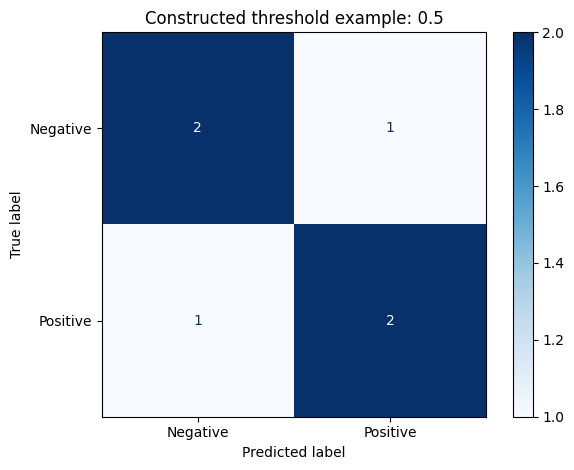

In [3]:
example_y = np.array([0, 0, 0, 1, 1, 1])
example_probabilities = np.array([0.1, 0.4, 0.8, 0.3, 0.7, 0.9])
example_labels = (example_probabilities >= 0.5).astype(int)
matrix = confusion_matrix(example_y, example_labels, labels=[0, 1])
tn, fp, fn, tp = matrix.ravel()
print("TN, FP, FN, TP:", tn, fp, fn, tp)
print("Accuracy:", accuracy_score(example_y, example_labels))
print("Precision / recall / F1:", precision_score(example_y, example_labels, zero_division=0),
      recall_score(example_y, example_labels, zero_division=0), f1_score(example_y, example_labels, zero_division=0))
ConfusionMatrixDisplay(matrix, display_labels=["Negative", "Positive"]).plot(cmap="Blues")
plt.title("Constructed threshold example: 0.5"); plt.tight_layout(); plt.show()

**Interpretation:** Rows are actual classes and columns are predicted classes. The example gives TN=2, FP=1, FN=1, TP=2, so accuracy, precision, recall, and F1 are all 2/3.

**Things to Remember:** These known toy results demonstrate definitions, not the saved model's performance. Confusion-matrix ordering changes if labels changes; always specify labels=[0, 1].

### Technique: ROC-AUC and ROC curve

**What is it?** ROC-AUC evaluates probability ranking across decision thresholds.

**Why do we use it?** It separates ranking ability from one threshold-dependent decision.

**When should we use it?** Use probability scores for the positive class; ensure both classes exist in the evaluated data.

**Python Syntax / Example**

The following cell is a runnable example; adapt the column names and values to reuse it.

Constructed example AUC: 0.6666666666666667


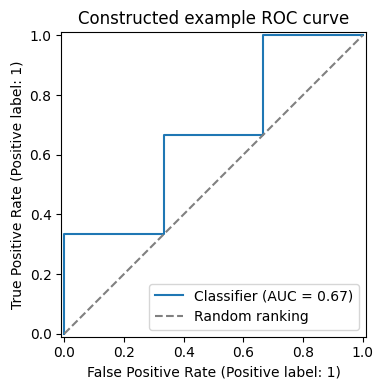

In [4]:
print("Constructed example AUC:", roc_auc_score(example_y, example_probabilities))
fig, ax = plt.subplots(figsize=(5, 4))
RocCurveDisplay.from_predictions(example_y, example_probabilities, ax=ax)
ax.plot([0, 1], [0, 1], "--", color="grey", label="Random ranking")
ax.set_title("Constructed example ROC curve")
ax.legend(); fig.tight_layout(); plt.show()

**Interpretation:** A curve toward the upper-left indicates stronger ranking. The curve does not tell us whether the selected operating point is affordable or whether estimated probabilities are accurate.

**Things to Remember:** Use probabilities or decision scores, not hard labels, for a meaningful AUC. AUC is undefined when only one actual class is present.

### Technique: Imbalanced classes and misleading accuracy

**What is it?** A majority-only classifier can score high accuracy while missing every positive.

**Why do we use it?** The cost of rare-event misses is often hidden by the class distribution.

**When should we use it?** For rare positives, prioritize metrics and thresholds based on decision consequences rather than accuracy alone.

**Python Syntax / Example**

The following cell is a runnable example; adapt the column names and values to reuse it.

In [5]:
imbalanced_y = np.array([0] * 95 + [1] * 5)
majority_predictions = np.zeros(100, dtype=int)
print("Constructed accuracy:", accuracy_score(imbalanced_y, majority_predictions))
print("Constructed positive recall:", recall_score(imbalanced_y, majority_predictions, zero_division=0))
print("Constructed positive precision:", precision_score(imbalanced_y, majority_predictions, zero_division=0))

Constructed accuracy: 0.95
Constructed positive recall: 0.0
Constructed positive precision: 0.0


**Interpretation:** Accuracy is 95% but recall is 0: all five positive cases were missed. Precision is reported as 0 under the explicit undefined-value convention.

**Things to Remember:** Recall may matter for expensive missed fraud; precision may matter when each investigation is costly. Usually both matter. A lower threshold changes the tradeoff; choose it before the final holdout.

## D. Cross-Validation

### Technique: K-Fold for regression and Stratified K-Fold for classification

**What is it?** CV rotates validation folds through training data; stratification approximately preserves class ratios.

**Why do we use it?** One split can be lucky or unlucky, so fold scores provide a more informative development comparison.

**When should we use it?** Use independent-observation splits here; use group/time CV when data dependencies require it.

**Python Syntax / Example**

The following cell is a runnable example; adapt the column names and values to reuse it.

In [6]:
regression_cv = KFold(n_splits=3, shuffle=True, random_state=42)
linear_cv_mae = -cross_val_score(clone(candidates["Linear regression"]), X_train, y_train,
                               cv=regression_cv, scoring="neg_mean_absolute_error", n_jobs=1)
class_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
class_template = clone(classification["models"][classification["selected_name"]])
class_cv_auc = cross_val_score(class_template, classification["X_train"], classification["y_train"],
                              cv=class_cv, scoring="roc_auc", n_jobs=1)
print("Linear CV MAE folds:", linear_cv_mae.round(2), "mean:", linear_cv_mae.mean().round(2))
print("Classifier CV AUC folds:", class_cv_auc.round(3), "mean:", class_cv_auc.mean().round(3))

Linear CV MAE folds: [20.71 18.52 23.4 ] mean: 20.88
Classifier CV AUC folds: [0.995 0.999 1.    0.987 0.998] mean: 0.996


**Interpretation:** Each fold refits both preparation and model. Scores vary because the fitting samples differ. CV improves selection reliability, but the fold results are not independent experiments or a guarantee of future performance.

**Things to Remember:** Do not present the best tuned CV score as an unbiased final estimate. Nested CV is an option for more rigorous selection assessment; it is outside this introductory workflow. Final holdouts remain untouched here.

## E. Model Comparison

The following tables load the evidence already used in 03. They do not recalculate validation performance with a pipeline that has subsequently seen validation outcomes.

In [7]:
display(comparison.round(3))
display(classification["comparison"].round(4))
print("Primary choice fixed before test:", selected_name)
print("Classification choice fixed before test:", classification["selected_name"])
print("Primary validation MAE improvement over median baseline:",
      round(comparison.loc["Median baseline", "validation_mae"] - comparison.loc[selected_name, "validation_mae"], 2), "IDR million")

,train_mae,validation_mae,validation_rmse,validation_r2
model,,,,
Linear regression,18.780,17.208,22.250,0.872
Decision tree,15.766,21.378,24.774,0.841
Grid-tuned tree,16.871,22.028,25.655,0.830
Gradient boosting,14.132,23.104,26.633,0.817
Random forest,15.463,23.240,27.688,0.802
Random-tuned forest,14.078,25.013,29.230,0.779
Median baseline,59.845,57.147,65.904,-0.122


,cv_auc_mean,cv_auc_std
model,,
Logistic regression,0.9958,0.0047
Random forest,0.9878,0.0075
Decision tree,0.9418,0.0318
Dummy classifier,0.5000,0.0000


Primary choice fixed before test: Linear regression
Classification choice fixed before test: Logistic regression
Primary validation MAE improvement over median baseline: 39.94 IDR million


**Interpretation:** Compare the primary validation MAE, RMSE, and R² alongside the training MAE. A larger training–validation gap can suggest overfitting, while a simple model with comparable validation performance is easier to explain and maintain. The classification table uses mean training-CV ROC-AUC, not classification test scores.

**Practical selection:** Consider latency, cost, stability, schema availability, and explainability. The demonstration's predetermined smallest-validation-MAE rule is already locked. Do not switch models after Section G; if test performance disappoints, report that limitation and obtain new evaluation evidence for future revisions.

## F. Model Interpretation

We use training-only fitted candidates and the existing validation set for interpretation. These are descriptive checks after selection, not new feature-selection steps. If they inspire model changes, those changes need a fresh development/evaluation cycle.

### Technique: Linear coefficient interpretation in original units

**What is it?** Coefficients describe conditional prediction changes when other included inputs are held fixed.

**Why do we use it?** Original units are easier to explain than scaled units.

**When should we use it?** Use with the exact fitted scaler and encoded reference categories.

**Python Syntax / Example**

The following cell is a runnable example; adapt the column names and values to reuse it.

In [8]:
linear = candidates["Linear regression"]
linear_prepare = linear.named_steps["prepare"]
linear_weights = pd.Series(linear.named_steps["model"].coef_, index=linear_prepare.get_feature_names_out())
display(linear_weights)
spending_scale = linear_prepare.named_transformers_["numeric"].named_steps["scaler"].scale_[0]
raw_spending_slope = linear_weights["numeric__promo_spend_million"] / spending_scale
print(f"Fitted sales change per IDR 1 million spending, same region: {raw_spending_slope:.3f} million IDR")
print("Region categories:", linear_prepare.named_transformers_["categorical"].named_steps["encoder"].categories_)

numeric__promo_spend_million    64.701098
categorical__region_Sumatra     -0.057263
dtype: float64

Fitted sales change per IDR 1 million spending, same region: 7.709 million IDR
Region categories: [array(['Java', 'Sumatra'], dtype=object)]


**Interpretation:** Dividing the standardized spending weight by the training scale yields a per-IDR-million slope. The one-hot coefficient is a predicted difference relative to the first, dropped region category.

**Things to Remember:** These are conditional predictive associations; omitted drivers or selection effects can explain them. Scaling conversion alone does not make a coefficient causal. If inputs are strongly correlated, coefficients can be unstable.

### Technique: Tree impurity importance and held-out permutation importance

**What is it?** Impurity importance describes training split improvements; permutation importance measures how much a fixed model's held-out score worsens when one input is shuffled.

**Why do we use it?** Permutation importance measures reliance on a feature using the original input columns.

**When should we use it?** Compute on validation with a model that was not fitted on those rows; repeat shuffles to see variability.

**Python Syntax / Example**

The following cell is a runnable example; adapt the column names and values to reuse it.

In [9]:
forest = candidates["Random forest"]
forest_importance = pd.Series(forest.named_steps["model"].feature_importances_,
                             index=forest.named_steps["prepare"].get_feature_names_out())
display(forest_importance.sort_values(ascending=False))
permutation = permutation_importance(validation_model, X_validation, y_validation,
                                    scoring="neg_mean_absolute_error", n_repeats=20, random_state=42, n_jobs=1)
permutation_table = pd.DataFrame({"feature": X_validation.columns,
                                  "MAE_increase_mean": permutation.importances_mean,
                                  "shuffle_std": permutation.importances_std}).sort_values("MAE_increase_mean", ascending=False)
display(permutation_table.round(3))

numeric__promo_spend_million    0.993904
categorical__region_Sumatra     0.006096
dtype: float64

,feature,MAE_increase_mean,shuffle_std
0,promo_spend_million,58.231,10.171
1,region,0.013,0.005


**Interpretation:** With negative MAE scoring, a positive permutation importance is the increase in MAE after shuffling, in IDR million. Near-zero or negative importance means no clear benefit under this sample/model, not proof that a feature never matters.

**Things to Remember:** Correlated inputs can substitute for one another or produce unrealistic shuffled combinations. Importance is model- and sample-dependent. Repeated shuffles quantify shuffle variability, not full statistical uncertainty. Neither importance method establishes causality.

### Technique: Error analysis and subgroup checks

**What is it?** Residuals are actual minus predicted values. Group summaries expose where errors concentrate.

**Why do we use it?** An overall metric can hide systematic underprediction or subgroup problems.

**When should we use it?** Use validation residuals to diagnose the current model; preserve test data for the final report.

**Python Syntax / Example**

The following cell is a runnable example; adapt the column names and values to reuse it.

,promo_spend_million,region,store_id,actual,predicted,residual,absolute_error
69,8.8,Java,NM-070,226.3,166.545608,59.754392,59.754392
48,11.5,Sumatra,NM-049,150.9,187.302167,-36.402167,36.402167
76,12.2,Java,NM-077,223.3,192.755607,30.544393,30.544393
54,23.1,Java,NM-055,249.7,276.781780,-27.081780,27.081780
71,17.7,Java,NM-072,255.3,235.154134,20.145866,20.145866


,stores,mae,bias
region,,,
Java,13,18.594423,12.453015
Sumatra,4,12.704025,-9.254224


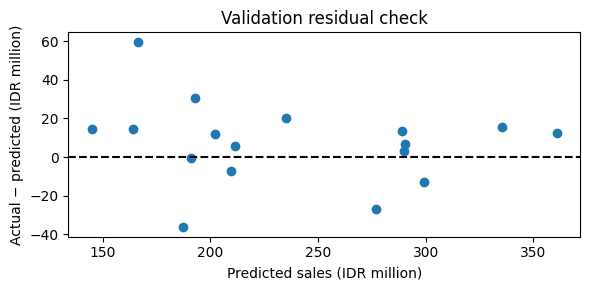

In [10]:
errors = X_validation.copy()
errors["store_id"] = bundle["validation_ids"]
errors["actual"] = y_validation
errors["predicted"] = validation_predictions
errors["residual"] = errors["actual"] - errors["predicted"]
errors["absolute_error"] = errors["residual"].abs()
display(errors.sort_values("absolute_error", ascending=False).head())
display(errors.groupby("region").agg(stores=("actual", "count"), mae=("absolute_error", "mean"), bias=("residual", "mean")))
fig, ax = plt.subplots(figsize=(6, 3))
ax.scatter(errors["predicted"], errors["residual"]); ax.axhline(0, color="black", linestyle="--")
ax.set(title="Validation residual check", xlabel="Predicted sales (IDR million)", ylabel="Actual − predicted (IDR million)")
fig.tight_layout(); plt.show()

**Interpretation:** Positive residuals mean underprediction. A systematic curve, changing spread, or consistent subgroup bias may signal missing structure. Inspect the largest errors against source records before deciding they are mistakes.

**Things to Remember:** Tiny subgroup counts limit conclusions. Do not remove hard observations to improve metrics. If you change the model based on these patterns, its future assessment must account for that development step.

## G. Final Model Evaluation — Open the Untouched Holdouts

**Decision gate:** All feature choices, algorithms, tuning, and classification thresholds are fixed. The regression pipeline has been refitted on 68 development rows. The separately selected classifier was fitted on its training set only. We now compute final scores without using them to choose another candidate.

This snapshot supports evaluation on unseen stores under the random-split assumptions; it does not demonstrate future-month forecasting performance, causal promotion effectiveness, or readiness for production.

### Technique: Load and evaluate the saved sales pipeline

**What is it?** The final pipeline accepts raw holdout feature columns and predicts with its saved preprocessing.

**Why do we use it?** An untouched holdout is the final check on generalization for this development cycle.

**When should we use it?** Compare the locked candidate and a fixed training-fitted baseline on the exact same test rows.

**Python Syntax / Example**

The following cell is a runnable example; adapt the column names and values to reuse it.

In [11]:
final_model = joblib.load("models/final_sales_pipeline.joblib")
final_baseline = joblib.load("models/final_sales_baseline.joblib")
X_test, y_test = bundle["X_test"], bundle["y_test"]
test_predictions = final_model.predict(X_test)
baseline_test_predictions = final_baseline.predict(X_test)
final_rows = []
for name, predicted in [(selected_name, test_predictions), ("Median baseline", baseline_test_predictions)]:
    final_rows.append({"model": name, "MAE": mean_absolute_error(y_test, predicted), "MSE": mean_squared_error(y_test, predicted),
                       "RMSE": root_mean_squared_error(y_test, predicted), "R2": r2_score(y_test, predicted)})
final_regression = pd.DataFrame(final_rows).set_index("model")
display(final_regression.round(3))

,MAE,MSE,RMSE,R2
model,,,,
Linear regression,25.763,956.132,30.921,0.743
Median baseline,51.294,3734.535,61.111,-0.004


**Interpretation:** All numerical errors except MSE are in IDR million; R² is unitless. The test baseline was fitted on development data, not test outcomes. Report both rows even if the chosen model underperforms.

**Things to Remember:** There are only 18 primary test stores. A single small holdout can be noisy; neither a good score nor a poor score is conclusive for every future store. Do not tune after seeing it.

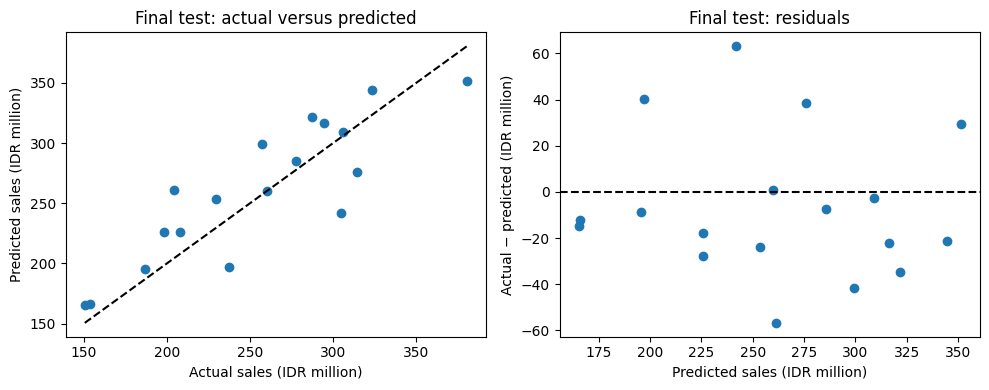

On 18 unseen stores, Linear regression has an average absolute miss of IDR 25.76 million.
Baseline MAE is IDR 51.29 million; model-minus-baseline MAE is -25.53 million (negative is better).


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
limits = [min(y_test.min(), test_predictions.min()), max(y_test.max(), test_predictions.max())]
axes[0].scatter(y_test, test_predictions)
axes[0].plot(limits, limits, "--", color="black")
axes[0].set(title="Final test: actual versus predicted", xlabel="Actual sales (IDR million)", ylabel="Predicted sales (IDR million)")
axes[1].scatter(test_predictions, y_test.to_numpy() - test_predictions)
axes[1].axhline(0, color="black", linestyle="--")
axes[1].set(title="Final test: residuals", xlabel="Predicted sales (IDR million)", ylabel="Actual − predicted (IDR million)")
fig.tight_layout(); plt.show()
test_mae = mean_absolute_error(y_test, test_predictions)
baseline_mae = mean_absolute_error(y_test, baseline_test_predictions)
print(f"On {len(y_test)} unseen stores, {selected_name} has an average absolute miss of IDR {test_mae:.2f} million.")
print(f"Baseline MAE is IDR {baseline_mae:.2f} million; model-minus-baseline MAE is {test_mae - baseline_mae:.2f} million (negative is better).")

**Interpretation:** The diagonal chart shows closeness of estimates; residuals show direction and variation of errors. Use the printed comparison to state what actually happened. Practical usefulness still depends on whether the error is acceptable for the business decision, whether inputs are available in time, and whether future stores resemble this sample. These diagnostics document the locked model; they do not trigger retuning here.

### Technique: Final classification holdout at a locked threshold

**What is it?** We evaluate the selected classifier once using its positive-class probabilities and the predetermined threshold.

**Why do we use it?** Classification needs both ranking evidence and threshold-specific error counts.

**When should we use it?** Report class prevalence and operational metrics, not accuracy alone.

**Python Syntax / Example**

The following cell is a runnable example; adapt the column names and values to reuse it.

In [13]:
class_model = classification["models"][classification["selected_name"]]
class_X_test, class_y_test = classification["X_test"], classification["y_test"]
positive_index = list(class_model.classes_).index(1)
class_probabilities = class_model.predict_proba(class_X_test)[:, positive_index]
class_labels = (class_probabilities >= classification["threshold"]).astype(int)
class_metrics = pd.Series({"accuracy": accuracy_score(class_y_test, class_labels),
                           "precision": precision_score(class_y_test, class_labels, zero_division=0),
                           "recall": recall_score(class_y_test, class_labels, zero_division=0),
                           "f1": f1_score(class_y_test, class_labels, zero_division=0),
                           "roc_auc": roc_auc_score(class_y_test, class_probabilities)})
display(class_metrics.round(4))
print("Positive prevalence:", class_y_test.mean(), "; fixed threshold:", classification["threshold"])

accuracy     0.9649
precision    0.9750
recall       0.9286
f1           0.9512
roc_auc      0.9960
dtype: float64

Positive prevalence: 0.3684210526315789 ; fixed threshold: 0.5


**Interpretation:** Precision describes predicted malignant cases; recall describes actual malignant cases found. The AUC measures ranking and may look strong even when a chosen threshold has unacceptable errors.

**Things to Remember:** Do not select a new threshold from these test outcomes. This dataset and demonstration do not establish clinical safety, calibration, or external validity.

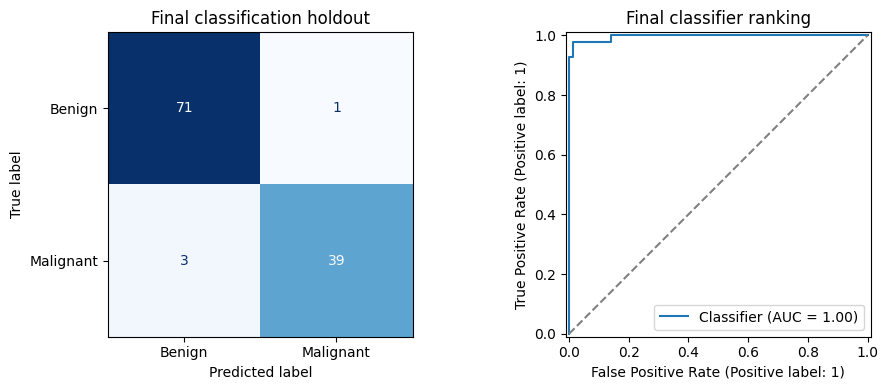

Held-out decisions: 39 true positives, 71 true negatives, 1 false positives, 3 false negatives.


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
class_matrix = confusion_matrix(class_y_test, class_labels, labels=[0, 1])
ConfusionMatrixDisplay(class_matrix, display_labels=["Benign", "Malignant"]).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Final classification holdout")
RocCurveDisplay.from_predictions(class_y_test, class_probabilities, ax=axes[1])
axes[1].plot([0, 1], [0, 1], "--", color="grey")
axes[1].set_title("Final classifier ranking")
fig.tight_layout(); plt.show()
tn, fp, fn, tp = class_matrix.ravel()
print(f"Held-out decisions: {tp} true positives, {tn} true negatives, {fp} false positives, {fn} false negatives.")

**Interpretation:** The counts reveal actual false-alarm and missed-case consequences at threshold 0.5. Use them alongside AUC rather than assuming a high summary score eliminates errors. Any future threshold or model revision requires separate development evidence and a fresh evaluation plan.

In [15]:
final_regression.to_csv("models/final_regression_test_metrics.csv")
class_metrics.to_csv("models/final_classification_test_metrics.csv", header=["value"])
print("Final reports saved. No model selection or tuning follows these scores.")

Final reports saved. No model selection or tuning follows these scores.


## H. Final Evaluation Checklist

- [ ] The target, positive class, units, prediction time, and business decision are explicit.
- [ ] Splits reflect future deployment, including time or group dependencies if present.
- [ ] All learned preprocessing and feature selection were fitted inside training/CV.
- [ ] Model/hyperparameter choices and thresholds were fixed before final holdout evaluation.
- [ ] The baseline is fitted on development data and compared on the same test rows.
- [ ] Metrics match the task and decision costs; regression and classification metrics are not mixed.
- [ ] Residual patterns, subgroup sample sizes, and error types are considered.
- [ ] Small-sample uncertainty, missing drivers, and limits of external validity are disclosed.
- [ ] The full pipeline, schema, versions, and test report are saved and reproducible.
- [ ] Deployment still needs input validation, monitoring, drift checks, and an acceptable-error decision.

**If the checklist fails:** Document the limitation. Improve the next development cycle and obtain new evaluation evidence. Do not repair the apparent test score by quietly tuning to this holdout.

## Summary and Quick Syntax Reference

| Goal | Reusable syntax |
|---|---|
| Regression absolute error | `mean_absolute_error(y, predictions)` |
| Squared / root-squared error | `mean_squared_error(y, predictions)` / `root_mean_squared_error(y, predictions)` |
| Relative regression fit | `r2_score(y, predictions)` |
| Classification counts | `confusion_matrix(y, labels, labels=[0, 1])` |
| Accuracy | `accuracy_score(y, labels)` |
| Positive precision / recall | `precision_score(y, labels, zero_division=0)` / `recall_score(...)` |
| Balance P and R | `f1_score(y, labels, zero_division=0)` |
| Ranking | `roc_auc_score(y, positive_probabilities)` |
| Fold scores | `cross_val_score(pipeline, X_train, y_train, cv=cv, scoring=...)` |
| Recover MAE from negative scores | `-cross_val_score(..., scoring="neg_mean_absolute_error")` |
| Permutation reliance | `permutation_importance(pipeline, X_validation, y_validation, scoring="neg_mean_absolute_error")` |
| Residual / absolute error | `actual - predicted` / `np.abs(actual - predicted)` |
| Restore inference pipeline | `joblib.load("models/final_sales_pipeline.joblib")` |

## Practice exercises
1. In the constructed confusion-matrix example, lower the threshold to 0.2. Recalculate TP/FP/TN/FN, precision, and recall. Explain the tradeoff. **Check:** more cases should be labeled positive. Do not alter the final model's threshold.
2. Using only the saved validation comparison, identify the model with the largest training–validation MAE gap. Explain why this is a warning sign rather than definitive proof of overfitting.
3. Write a five-sentence evaluation memo: selected model, test MAE and units, baseline comparison, one limitation, and one requirement before practical use. **Check:** quote computed scores, not hypothetical ones; do not propose changes based on a desire to improve this specific test score.

**Common mistakes:** calling R² accuracy, computing AUC from hard labels, ignoring the positive-class mapping, comparing training performance as if it were generalization, treating importance as causation, and revisiting model choice after seeing test scores.

**Handbook takeaway:** A useful model needs a clear problem, a reproducible pipeline, appropriate evaluation, and an honest account of what the evidence supports.